# Autocorrelation controls

This notebook tests the pre-onset results of `notebooks/prediction.ipynb` for sub-03 against nulls that keep the autocorrelation of the neural signal and the embeddings. We ask three questions: (1) whether the difference in encoding performance between predicted and unpredicted words from -1 to 0 s is larger than chance, (2) whether the GPT-2 XL encoding model performs above chance before word onset, and (3) how much of that pre-onset performance comes from the previous word's embedding, and whether the current word adds anything beyond it. Both nulls use circular shifts, which slide one sequence against the other and wrap the end around to the start.

Run `make controls` before this notebook.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nilearn import datasets
from nilearn.plotting import plot_markers
from statsmodels.stats.multitest import multipletests

from utils import load_results, get_coord_atlas_labels, generate_null_dist, calculate_pvalues

plt.style.use("figures.mplstyle")
Path("../figures/controls").mkdir(parents=True, exist_ok=True)

## Loading results

The result file holds the encoding performance of the current-word, previous-word, and joint models for each fold, the observed predicted minus unpredicted difference per electrode, and the two null distributions, one value per shift and electrode.

In [2]:
result_file = "../results/sub-03/controls/sub-03_task-podcast_desc-gpt2.xl.l24_result.h5"

with h5py.File(result_file, "r") as f:
    for key in f.keys():
        print(f"{key} has a shape of: {f[key].shape}")
    scores = f["scores"][...]  # folds x electrodes x lags
    scores_prev = f["scores_prev"][...]
    scores_joint = f["scores_joint"][...]
    obs_diff = f["obs_diff"][...]  # electrodes
    null_diff = f["null_diff"][...]  # shifts x electrodes
    null_r = f["null_r"][...]  # models x shifts x electrodes
    offsets = f["offsets"][...]
    window = f["window"][...]
    lags = f["lags"][...]
    coords = f["coords"][...]
    ch_names = f["ch_names"][...].astype(str)
    n_draws, min_shift = f.attrs["n_draws"], f.attrs["min_shift"]

ch_names has a shape of: (235,)
coords has a shape of: (235, 3)
lags has a shape of: (128,)
null_diff has a shape of: (1000, 235)
null_r has a shape of: (3, 1000, 235)
obs_diff has a shape of: (235,)
offsets has a shape of: (2, 1000)
scores has a shape of: (2, 235, 128)
scores_joint has a shape of: (2, 235, 128)
scores_prev has a shape of: (2, 235, 128)
window has a shape of: (128,)


## Significant electrodes

We pick electrodes with the same test as the paper on the encoding performance for all words, so the selection cannot favor either word group.

In [3]:
null_dist = generate_null_dist()  # same size and seed as the paper's code

p_values = calculate_pvalues(scores.mean(0).max(-1), null_dist)
sig_mask = multipletests(p_values, alpha=0.01, method="fdr_bh")[0]
print(f"{sig_mask.sum()} of {len(sig_mask)} electrodes are significant")
assert sig_mask.sum() == 185  # same electrodes as prediction.ipynb

185 of 235 electrodes are significant


## Predicted against unpredicted words

The label-shift null slides the predicted labels against the words by at least 100 words, which keeps the autocorrelation of the labels, the neural signal, and the model predictions but breaks the link between a word's label and its activity.

Observed difference: -0.0023
Two-sided p = 0.0569, one-sided p (predicted > unpredicted) = 0.9680


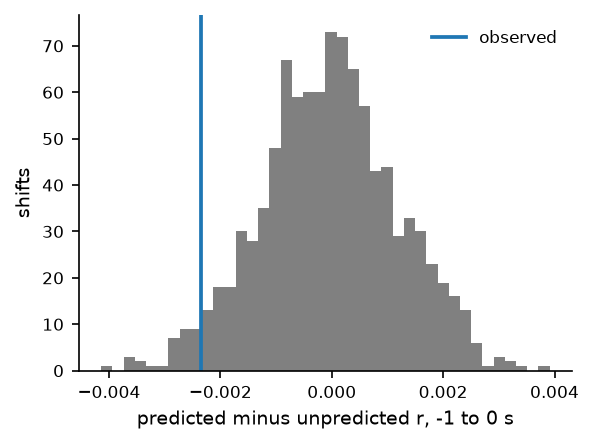

In [4]:
obs = obs_diff[sig_mask].mean()
null = null_diff[:, sig_mask].mean(1)

p_two = (1 + (np.abs(null) >= np.abs(obs)).sum()) / (1 + len(null))
p_greater = (1 + (null >= obs).sum()) / (1 + len(null))  # predicted greater than unpredicted
print(f"Observed difference: {obs:.4f}")
print(f"Two-sided p = {p_two:.4f}, one-sided p (predicted > unpredicted) = {p_greater:.4f}")

fig, ax = plt.subplots(figsize=(4, 3), layout="tight")
ax.hist(null, bins=40, color="gray")
ax.axvline(obs, color=plt.get_cmap("tab20")(0), lw=1.8, label="observed")
ax.locator_params(axis="x", nbins=5)
ax.set_xlabel("predicted minus unpredicted r, -1 to 0 s")
ax.set_ylabel("shifts")
ax.legend(loc="best")
fig.savefig("../figures/controls/sub-03-label-null.svg")
plt.show()

## Encoding before word onset

The prediction-shift null slides each model's predictions against the neural data by the same offsets, which keeps the autocorrelation of both but breaks their alignment in time.

In [5]:
models = ["current", "previous", "joint"]
model_scores = [scores, scores_prev, scores_joint]

rows = []
for m, (modelname, model_score) in enumerate(zip(models, model_scores)):
    observed = model_score.mean(0)[sig_mask][:, window].mean()
    null = null_r[m][:, sig_mask].mean(1)
    p = (1 + (null >= observed).sum()) / (1 + len(null))
    rows.append([modelname, observed, np.percentile(null, 95), p])

window_table = pd.DataFrame(rows, columns=["model", "observed r", "null 95th percentile", "p"])
window_table.round(4)

,model,observed r,null 95th percentile,p
0,current,0.0214,0.0015,0.001
1,previous,0.0232,0.0015,0.001
2,joint,0.0255,0.0017,0.001


## What the previous word explains

We define the unique variance of the current word as the joint model's r² minus the previous-word model's r², with negative correlations clipped at 0 first.

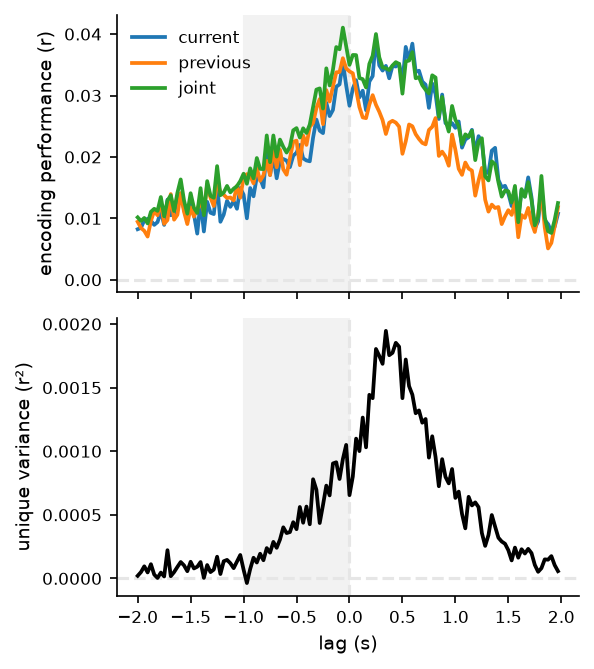

Observed unique variance: 0.000400
Null 95th percentile: 0.000008, p = 0.0010


In [6]:
colors = plt.get_cmap("tab20")([0, 2, 4])
curves = [model_score.mean(0)[sig_mask].mean(0) for model_score in model_scores]
unique = (np.clip(scores_joint.mean(0), 0, None) ** 2
          - np.clip(scores_prev.mean(0), 0, None) ** 2)[sig_mask].mean(0)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(4, 4.5), layout="tight")
for ax in axes:
    ax.axvspan(-1, 0, color=(.95, .95, .95), zorder=0)
    ax.axvline(0, c=(.9, .9, .9), ls="--")
    ax.axhline(0, c=(.9, .9, .9), ls="--")

for modelname, curve, color in zip(models, curves, colors):
    axes[0].plot(lags, curve, color=color, label=modelname, lw=1.8)
axes[0].set_ylabel("encoding performance (r)")
axes[0].legend(loc="best")

axes[1].plot(lags, unique, color="k", lw=1.8)
axes[1].set_xlabel("lag (s)")
axes[1].set_ylabel("unique variance (r²)")
fig.savefig("../figures/controls/sub-03-previous-word.svg")
plt.show()

# window-mean r per electrode, then the same formula
joint_window = scores_joint.mean(0)[:, window].mean(-1)
prev_window = scores_prev.mean(0)[:, window].mean(-1)
obs_unique = (np.clip(joint_window, 0, None) ** 2 - np.clip(prev_window, 0, None) ** 2)[sig_mask].mean()
null_unique = (np.clip(null_r[2], 0, None) ** 2 - np.clip(null_r[1], 0, None) ** 2)[:, sig_mask].mean(1)
p_unique = (1 + (null_unique >= obs_unique).sum()) / (1 + len(null_unique))
print(f"Observed unique variance: {obs_unique:.6f}")
print(f"Null 95th percentile: {np.percentile(null_unique, 95):.6f}, p = {p_unique:.4f}")

In sub-03, the difference between predicted and unpredicted words from -1 to 0 s (r = -0.0023) fell inside the label-shift null (two-sided p = 0.057). All three models performed above the prediction-shift null in the window (p = 0.001 each), with the previous-word model (r = 0.0232) above the current-word model (r = 0.0214), and the current word added unique variance beyond the previous word (0.00040 against a null 95th percentile of 0.000008, p = 0.001). These results come from one subject.